### **Image Moments, Orientation, and Hu Moments**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/08_Hu_Moments.ipynb)

> **Image moments** summarize a shape with a few numbers: area, centroid, and orientation. The seven **Hu moments** combine them into values that do not change when the shape is moved, resized, or rotated, which makes them useful for shape matching. The seventh one changes sign when the shape is **mirrored**.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

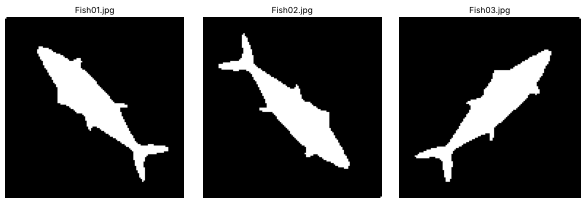

In [2]:
# Load the three fish silhouettes as binary masks (fish = white)
def fish_mask(name):
    gray = load_image(name, cv2.IMREAD_GRAYSCALE)
    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return mask

masks = {name: fish_mask(name) for name in ["Fish01.jpg", "Fish02.jpg", "Fish03.jpg"]}
show(list(masks.values()), list(masks), size=(12, 4))

#### **01. Centroid and Orientation**

From the raw moments `m` and central moments `mu`:

* **Centroid:** `cx = m10 / m00`, `cy = m01 / m00`.
* **Orientation** of the main axis: `θ = ½ · atan2(2·mu11, mu20 − mu02)`.

Image rows grow downward, so the angle is converted to the usual counterclockwise convention (0° to 180°).

Fish01.jpg: area=1965 px, centroid=(60, 59), orientation=134.4°
Fish02.jpg: area=1965 px, centroid=(62, 64), orientation=134.4°
Fish03.jpg: area=1965 px, centroid=(64, 60), orientation=44.4°


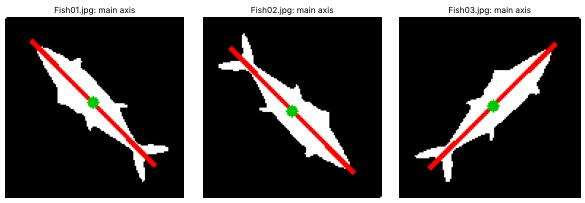

In [3]:
# Centroid and orientation of each fish, drawn on the image
def orientation(mask):
    M = cv2.moments(mask, binaryImage=True)
    cx, cy = M["m10"] / M["m00"], M["m01"] / M["m00"]
    theta = 0.5 * np.arctan2(2 * M["mu11"], M["mu20"] - M["mu02"])   # clockwise, image axes
    angle = (-np.degrees(theta)) % 180                               # counterclockwise, 0-180
    return M, (cx, cy), theta, angle

drawings = []
for name, mask in masks.items():
    M, (cx, cy), theta, angle = orientation(mask)
    print(f"{name}: area={M['m00']:.0f} px, centroid=({cx:.0f}, {cy:.0f}), orientation={angle:.1f}°")
    canvas = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
    dx, dy = 60 * np.cos(theta), 60 * np.sin(theta)
    cv2.line(canvas, (int(cx - dx), int(cy - dy)), (int(cx + dx), int(cy + dy)), (0, 0, 255), 2)
    cv2.circle(canvas, (int(cx), int(cy)), 4, (0, 200, 0), -1)
    drawings.append(canvas)
show(drawings, [f"{n}: main axis" for n in masks], size=(12, 4))

#### **02. Hu Moments: Invariance**

Hu moments span many orders of magnitude, so they are compared on a log scale: `−sign(h) · log10(|h|)`. Below, the three fish are compared with **scaled** and **mirrored** versions of Fish01, using the sum of absolute differences of the log-scaled moments as a distance (0 = same shape).

In [4]:
# Log-scaled Hu moments for the fish, a scaled copy, and a mirrored copy
np.set_printoptions(suppress=True)
def log_hu(mask):
    hu = cv2.HuMoments(cv2.moments(mask, binaryImage=True)).ravel()
    return -np.sign(hu) * np.log10(np.abs(hu))

reference = masks["Fish01.jpg"]
variants = dict(masks)
variants["Fish01 scaled x2"] = cv2.resize(reference, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST)
variants["Fish01 mirrored"] = cv2.flip(reference, 1)

ref = log_hu(reference)
print(f"{'shape':<18}" + "".join(f"{'h' + str(i):>7}" for i in range(1, 8)) + f"{'dist h1-h6':>12}{'dist h1-h7':>12}")
for name, mask in variants.items():
    values = log_hu(mask)
    diff = np.abs(values - ref)
    print(f"{name:<18}" + "".join(f"{v:7.2f}" for v in values) + f"{diff[:6].sum():12.3f}{diff.sum():12.3f}")

shape                  h1     h2     h3     h4     h5     h6     h7  dist h1-h6  dist h1-h7
Fish01.jpg           0.37   0.82   2.19   2.16   4.34   2.58  -6.62       0.000       0.000
Fish02.jpg           0.37   0.82   2.19   2.16   4.34   2.58  -6.62       0.000       0.000
Fish03.jpg           0.37   0.82   2.19   2.16   4.34   2.58  -6.62       0.000       0.000
Fish01 scaled x2     0.37   0.82   2.19   2.16   4.34   2.58  -6.62       0.000       0.000
Fish01 mirrored      0.37   0.82   2.19   2.16   4.34   2.58   6.62       0.000      13.232


#### **Key Takeaways**

* Fish02 and Fish03 are the same shape as Fish01 in other positions and rotations: their Hu moments are practically identical.
* Scaling keeps the moments (small differences come from resampling).
* Mirroring keeps h1 to h6 and **flips the sign of h7**: the distance using h1 to h6 stays near 0, while the distance including h7 jumps. Use h1 to h6 to match a shape and its mirror image as the same object, or include h7 to tell them apart.